

```
We load the standard Fashion-MNIST test split and generate the blur, darkening, and brightening conditions later in the notebook.
```

# 1. Load Data Set and Model

In [ ]:
# Install the library used to download the model from Hugging Face.
%pip install -q huggingface_hub

In [ ]:
from torchvision.datasets import FashionMNIST

# Load the test set. No training data is needed at this stage.
test_dataset = FashionMNIST(
    root="/content/data",
    train=False,
    download=True
)

print("Number of test images:", len(test_dataset))
print("Categories:", test_dataset.classes)

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 312kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.65MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 17.1MB/s]

Number of test images: 10000
Categories: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [ ]:
from huggingface_hub import HfApi, hf_hub_download

repo_id = "tsilva/fashionmnist-classifier-cnn"

# Record the exact model version so the experiment is reproducible.
revision = HfApi().model_info(repo_id).sha

model_folder = "/content/model"

for filename in [
    "model.ckpt",
    "modeling.py",
    "config.yaml",
    "label_mapping.json",
]:
    hf_hub_download(
        repo_id=repo_id,
        filename=filename,
        revision=revision,
        local_dir=model_folder
    )
    print("Downloaded:", filename)

print("\nModel version:", revision)

model.ckpt: reconstructing file:   0%|          |  0.00B / 18.5MB            

model.ckpt: downloading bytes:           |  0.00B            

Downloaded: model.ckpt


modeling.py:   0%|          | 0.00/2.51k [00:00<?, ?B/s]

Downloaded: modeling.py


config.yaml:   0%|          | 0.00/3.29k [00:00<?, ?B/s]

Downloaded: config.yaml


label_mapping.json:   0%|          | 0.00/179 [00:00<?, ?B/s]

Downloaded: label_mapping.json

Model version: 8b068e4063f2b03ea91651b0fa5877550616d6ae


In [ ]:
import torch

#Inspect the downloaded model files
for name in ["label_mapping.json", "config.yaml"]:
    print(f"=== {name} ===")
    with open(f"/content/model/{name}") as f:
        print(f.read())

print("=== model.ckpt keys ===")

ckpt = torch.load("/content/model/model.ckpt", map_location="cpu", weights_only=False)
if isinstance(ckpt, dict):
    print("Top-level keys:", list(ckpt.keys()))
    sd = ckpt.get("state_dict", ckpt)
    if isinstance(sd, dict):
        print("Sample state_dict keys:", list(sd.keys())[:10])

=== label_mapping.json ===
{
  "0": "T-shirt/top",
  "1": "Trouser",
  "2": "Pullover",
  "3": "Dress",
  "4": "Coat",
  "5": "Sandal",
  "6": "Shirt",
  "7": "Sneaker",
  "8": "Bag",
  "9": "Ankle boot"
}

=== config.yaml ===
dataset:
  name: fashion_mnist
  data_dir: datasets
  batch_size: 512
  num_workers: 16
  val_split: 0.1
  normalize: true
  download: true
  pin_memory: null
  augmentation:
    enabled: true
    random_affine:
      degrees: 10
      translate: 0.05
      scale:
      - 0.9
      - 1.1
      fill: 0
model:
  name: cnn
  params:
    channels:
    - 64
    - 128
    - 256
    dropout: 0.2
optimizer:
  name: adam
  lr: 0.001
  weight_decay: 3.0e-05
  params:
    betas:
    - 0.9
    - 0.999
  scheduler:
    name: cosine
    eta_min: 0.0
    pct_start: 0.25
    div_factor: 10.0
    final_div_factor: 100.0
trainer:
  max_epochs: 100
  accelerator: auto
  devices: auto
  precision: 32
  gradient_clip_val: 1.0
  deterministic: true
  log_every_n_steps: 20
  enable_che


# 2. Load the Pretrained CNN and Verify Clean Accuracy

In [ ]:
import sys, json, torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms
from huggingface_hub import hf_hub_download

sys.path.append("/content/model")
from modeling import load_model

# 1. Check README.md and checkpoint hyper_parameters for normalization stats
readme_path = hf_hub_download(repo_id="tsilva/fashionmnist-classifier-cnn", filename="README.md", revision=revision, local_dir="/content/model")
print("=== README.md ===")
print(open(readme_path).read())

ckpt = torch.load("/content/model/model.ckpt", map_location="cpu", weights_only=False)
print("=== hyper_parameters ===")
print(ckpt.get("hyper_parameters"))

# 2. Load model to GPU/CPU in eval mode
device = "cuda" if torch.cuda.is_available() else "cpu"
model = load_model("/content/model/model.ckpt", map_location=device).to(device).eval()

with open("/content/model/label_mapping.json") as f:
    label_map = {int(k): v for k, v in json.load(f).items()}

# 3. Quick check of clean accuracy under common Fashion-MNIST normalizations
def eval_clean(mean, std):
    tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((mean,), (std,))])
    ds = test_dataset
    imgs = torch.stack([tf(img) for img, _ in ds])
    labels = torch.tensor([y for _, y in ds])
    correct = 0
    with torch.no_grad():
        for i in range(0, len(imgs), 512):
            preds = model(imgs[i:i+512].to(device)).argmax(dim=-1).cpu()
            correct += (preds == labels[i:i+512]).sum().item()
    return correct / len(ds)

for name, (m, s) in [
    ("Raw [0,1]", (0.0, 1.0)),
    ("Standard (0.5, 0.5)", (0.5, 0.5)),
    ("FMNIST stats (0.2860, 0.3530)", (0.2860, 0.3530)),
]:
    print(f"Clean accuracy [{name}]: {eval_clean(m, s):.4f}")

README.md:   0%|          | 0.00/3.95k [00:00<?, ?B/s]

=== README.md ===
---
license: mit
library_name: onnx
pipeline_tag: image-classification
tags:
- image-classification
- fashion-mnist
- onnx
- onnxruntime
- pytorch
- dlab
datasets:
- zalando-datasets/fashion_mnist
metrics:
- accuracy
---

# Fashion-MNIST CNN Classifier

This repository contains a validation-selected shallow CNN classifier for Fashion-MNIST, trained with [dlab](https://github.com/tsilva/dlab).

## Architecture

![Fashion-MNIST CNN architecture](assets/architecture.png)

## Results

Seed-confirmed validation performance for this recipe, plus the final one-time test-set evaluation performed after checkpoint selection:

| metric | value |
|---|---:|
| validation loss | 0.2650 ± 0.0098 |
| validation accuracy | 95.14% ± 0.19 pp |
| test loss | 0.2791 |
| test accuracy | 94.76% |
| test correct | 9476 / 10000 |

The ONNX model was exported from the best validation-loss checkpoint from the selected recipe. The test metrics were not used to select the checkpoint and were logg




# 3. Define and Preview Image Corruptions

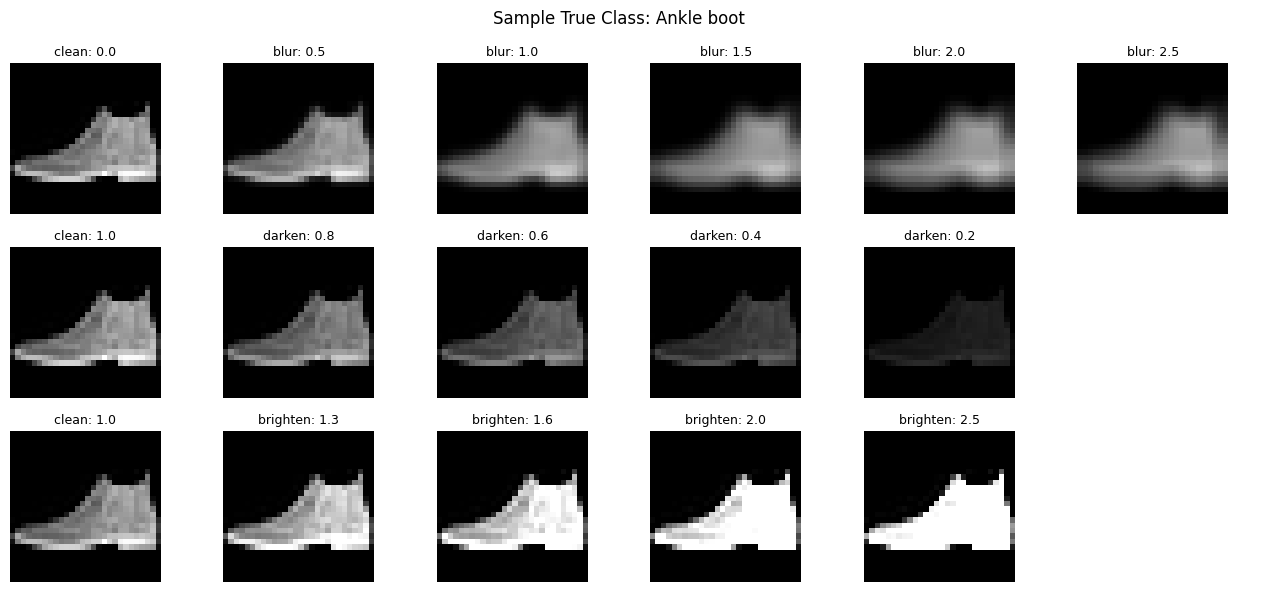

In [ ]:
import torch
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt

MEAN, STD = 0.2860, 0.3530

CORRUPTIONS = {
    "clean": [0.0],
    "blur": [0.5, 1.0, 1.5, 2.0, 2.5],          # Gaussian blur sigma (kernel_size=5)
    "darken": [0.8, 0.6, 0.4, 0.2],             # Brightness factor < 1
    "brighten": [1.3, 1.6, 2.0, 2.5],           # Brightness factor > 1
}

def apply_corruption(img_tensor, c_type, severity):
    """Expects img_tensor of shape (..., 28, 28) in [0, 1]. Returns tensor in [0, 1]."""
    if c_type == "clean":
        return img_tensor
    elif c_type == "blur":
        return TF.gaussian_blur(img_tensor, kernel_size=5, sigma=float(severity))
    elif c_type in ("darken", "brighten"):
        return TF.adjust_brightness(img_tensor, float(severity))
    raise ValueError(f"Unknown corruption: {c_type}")

# Preview all corruption levels on one test image (index 0 = Ankle boot; change idx to check others)
sample_pil, sample_y = test_dataset[0]
sample_img = TF.to_tensor(sample_pil)

fig, axes = plt.subplots(3, 6, figsize=(13, 6))
rows = [
    ("blur", [0.0] + CORRUPTIONS["blur"]),
    ("darken", [1.0] + CORRUPTIONS["darken"]),
    ("brighten", [1.0] + CORRUPTIONS["brighten"]),
]

for r_idx, (c_type, sevs) in enumerate(rows):
    for c_idx in range(6):
        ax = axes[r_idx, c_idx]
        if c_idx < len(sevs):
            sev = sevs[c_idx]
            mode = "clean" if (c_idx == 0) else c_type
            corrupted = apply_corruption(sample_img, mode, sev)
            ax.imshow(corrupted.squeeze(0), cmap="gray", vmin=0, vmax=1)
            ax.set_title(f"{mode}: {sev}", fontsize=9)
        ax.axis("off")

plt.suptitle(f"Sample True Class: {label_map[sample_y]}", fontsize=12)
plt.tight_layout()
plt.show()




# 4. Evaluate the CNN accross Corruption Conditions

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from tqdm.auto import tqdm

# Pre-convert all 10,000 clean test images once to a (10000, 1, 28, 28) tensor in [0, 1]
clean_imgs = torch.stack([TF.to_tensor(img) for img, _ in test_dataset])
true_labels = torch.tensor([y for _, y in test_dataset], dtype=torch.long)

batch_size = 512
records = []

conditions = [
    (c_type, sev)
    for c_type, sevs in CORRUPTIONS.items()
    for sev in sevs
]

model.eval()
with torch.no_grad():
    for c_type, sev in tqdm(conditions, desc="Evaluating conditions"):
        for start in range(0, len(clean_imgs), batch_size):
            end = min(start + batch_size, len(clean_imgs))
            batch = clean_imgs[start:end]
            y_true = true_labels[start:end]

            # 1. Corrupt in [0, 1], then normalize with exact model stats
            corrupted = apply_corruption(batch, c_type, sev)
            x = ((corrupted - MEAN) / STD).to(device)

            # 2. Black-box forward pass -> probabilities
            logits = model(x)
            probs = F.softmax(logits, dim=-1).cpu()

            top3_probs, top3_idx = torch.topk(probs, k=3, dim=-1)
            pred_idx = top3_idx[:, 0]
            pred_conf = top3_probs[:, 0]
            second_idx = top3_idx[:, 1]
            second_conf = top3_probs[:, 1]
            true_conf = probs[torch.arange(len(y_true)), y_true]
            entropy = -(probs * torch.log(probs + 1e-12)).sum(dim=-1)

            for i in range(len(y_true)):
                t_i = int(y_true[i])
                p_i = int(pred_idx[i])
                s_i = int(second_idx[i])
                top3_str = ", ".join(
                    f"{label_map[int(top3_idx[i, k])]} ({float(top3_probs[i, k]):.2f})"
                    for k in range(3)
                )
                records.append({
                    "image_id": start + i,
                    "corruption_type": c_type,
                    "severity": float(sev),
                    "true_idx": t_i,
                    "true_label": label_map[t_i],
                    "pred_idx": p_i,
                    "pred_label": label_map[p_i],
                    "is_correct": (p_i == t_i),
                    "pred_confidence": float(pred_conf[i]),
                    "true_class_confidence": float(true_conf[i]),
                    "second_pred_label": label_map[s_i],
                    "confidence_margin": float(pred_conf[i] - second_conf[i]),
                    "entropy": float(entropy[i]),
                    "top3_preds": top3_str,
                })

df = pd.DataFrame(records)
df.to_csv("/content/phase1_results.csv", index=False)
print(f"Saved {len(df):,} rows to /content/phase1_results.csv\n")

summary = (
    df.groupby(["corruption_type", "severity"], as_index=False)
      .agg(
          accuracy=("is_correct", "mean"),
          mean_conf=("pred_confidence", "mean"),
          mean_conf_correct=("pred_confidence", lambda s: s[df.loc[s.index, "is_correct"]].mean()),
          mean_conf_wrong=("pred_confidence", lambda s: s[~df.loc[s.index, "is_correct"]].mean()),
      )
)
print(summary.to_string(index=False))

Evaluating conditions:   0%|          | 0/14 [00:00<?, ?it/s]

Saved 140,000 rows to /content/phase1_results.csv

corruption_type  severity  accuracy  mean_conf  mean_conf_correct  mean_conf_wrong
           blur       0.5    0.9348   0.925889           0.942923         0.681662
           blur       1.0    0.7664   0.755259           0.798618         0.613005
           blur       1.5    0.6159   0.652734           0.709356         0.561942
           blur       2.0    0.5721   0.621668           0.681951         0.541069
           blur       2.5    0.5535   0.612309           0.677687         0.531264
       brighten       1.3    0.9106   0.926059           0.945823         0.724746
       brighten       1.6    0.8701   0.910940           0.939192         0.721699
       brighten       2.0    0.8383   0.899595           0.933853         0.721992
       brighten       2.5    0.8182   0.891098           0.928459         0.722951
          clean       0.0    0.9476   0.941834           0.954763         0.708029
         darken       0.2    0.8033 




# 5. Create Prediction Errors in the Dashboard

In [ ]:
import pandas as pd
import numpy as np
import torch
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# Load the results and images if needed.
if "df" not in globals():
    df = pd.read_csv("/content/phase1_results.csv")

if "clean_imgs" not in globals():
    clean_imgs = torch.stack([
        TF.to_tensor(img) for img, _ in test_dataset
    ])

if "label_map" not in globals():
    label_map = {
        0: "T-shirt/top",
        1: "Trouser",
        2: "Pullover",
        3: "Dress",
        4: "Coat",
        5: "Sandal",
        6: "Shirt",
        7: "Sneaker",
        8: "Bag",
        9: "Ankle boot",
    }

CLASSES = [label_map[i] for i in range(10)]

# Each track runs from clean to increasing corruption.
TRACK_STEPS = {
    "blur": [
        ("clean", 0.0, "Clean (σ=0.0)"),
        ("blur", 0.5, "σ=0.5"),
        ("blur", 1.0, "σ=1.0"),
        ("blur", 1.5, "σ=1.5"),
        ("blur", 2.0, "σ=2.0"),
        ("blur", 2.5, "σ=2.5"),
    ],
    "darken": [
        ("clean", 0.0, "Clean (1.0x)"),
        ("darken", 0.8, "0.8x"),
        ("darken", 0.6, "0.6x"),
        ("darken", 0.4, "0.4x"),
        ("darken", 0.2, "0.2x"),
    ],
    "brighten": [
        ("clean", 0.0, "Clean (1.0x)"),
        ("brighten", 1.3, "1.3x"),
        ("brighten", 1.6, "1.6x"),
        ("brighten", 2.0, "2.0x"),
        ("brighten", 2.5, "2.5x"),
    ],
}

clean_df = (
    df[df["corruption_type"] == "clean"]
    .set_index("image_id", verify_integrity=True)
)

# Interactive controls.
w_track = widgets.ToggleButtons(
    options=["blur", "darken", "brighten"],
    description="Track:",
)

w_step = widgets.SelectionSlider(
    options=[label for _, _, label in TRACK_STEPS["blur"]],
    value="σ=1.5",
    description="Severity:",
    continuous_update=False,
    layout=widgets.Layout(width="420px"),
)

w_true = widgets.Dropdown(
    options=["All"] + CLASSES,
    value="All",
    description="True Class:",
)

w_pred = widgets.Dropdown(
    options=["Any Wrong", "All"] + CLASSES,
    value="Any Wrong",
    description="Pred Class:",
)

w_min_conf = widgets.FloatSlider(
    value=0.0,
    min=0.0,
    max=1.0,
    step=0.05,
    description="Min Conf:",
    continuous_update=False,
)

w_n_imgs = widgets.IntSlider(
    value=8,
    min=4,
    max=16,
    step=4,
    description="Gallery #:",
    continuous_update=False,
)

w_new_errors = widgets.Checkbox(
    value=True,
    description="Only new errors",
)

out_charts = widgets.Output()
out_gallery = widgets.Output()


def update_dashboard(*_):
    track = w_track.value
    steps = TRACK_STEPS[track]
    step_labels = [label for _, _, label in steps]

    # Ignore a stale severity value during a track change.
    if w_step.value not in step_labels:
        return

    cur_idx = step_labels.index(w_step.value)
    cur_c_type, cur_sev, cur_lbl = steps[cur_idx]

    cur_df = df[
        (df["corruption_type"] == cur_c_type)
        & (df["severity"] == cur_sev)
    ]

    # Collect all conditions in the selected track.
    track_frames = []
    for corruption, severity, label in steps:
        sub = df[
            (df["corruption_type"] == corruption)
            & (df["severity"] == severity)
        ].copy()
        sub["step_label"] = label
        track_frames.append(sub)

    track_df = pd.concat(track_frames, ignore_index=True)

    with out_charts:
        clear_output(wait=True)

        fig, (ax1, ax2, ax3) = plt.subplots(
            1,
            3,
            figsize=(19, 5.2),
            gridspec_kw={"width_ratios": [1.15, 1.25, 1.0]},
        )

        # 1. Per-class accuracy across the selected track.
        acc_curve = (
            track_df.groupby(["step_label", "true_label"])["is_correct"]
            .mean()
            .unstack()
            .reindex(step_labels)
        )

        x_pos = np.arange(len(step_labels))
        cmap = plt.get_cmap("tab10")

        for i, cls in enumerate(CLASSES):
            is_focus = w_true.value == "All" or w_true.value == cls

            ax1.plot(
                x_pos,
                acc_curve[cls].values * 100,
                marker="o",
                markersize=5,
                color=cmap(i),
                linewidth=2.8 if w_true.value == cls else 1.5,
                alpha=1.0 if is_focus else 0.18,
                label=cls,
                zorder=5 if w_true.value == cls else 2,
            )

        ax1.axvline(
            cur_idx,
            color="black",
            linestyle="--",
            linewidth=1.4,
            label="Selected",
        )
        ax1.set_xticks(x_pos)
        ax1.set_xticklabels(
            step_labels, rotation=25, ha="right", fontsize=8.5
        )
        ax1.set_ylim(0, 103)
        ax1.set_ylabel("Accuracy (%)")
        ax1.set_title(f"Per-Class Accuracy ({track})")
        ax1.grid(alpha=0.25)
        ax1.legend(fontsize=7.5, ncol=2, loc="lower left")

        # 2. Confusion matrix with row percentages as colors.
        cm = pd.crosstab(
            cur_df["true_label"], cur_df["pred_label"]
        ).reindex(
            index=CLASSES,
            columns=CLASSES,
            fill_value=0,
        )

        cm_pct = (
            cm.div(cm.sum(axis=1).replace(0, 1), axis=0) * 100
        )

        matrix_image = ax2.imshow(
            cm_pct.values,
            cmap="Blues",
            vmin=0,
            vmax=100,
            aspect="auto",
        )

        for r in range(len(CLASSES)):
            for c in range(len(CLASSES)):
                count = int(cm.values[r, c])
                if count > 0:
                    text_color = (
                        "white" if cm_pct.values[r, c] > 50 else "black"
                    )
                    ax2.text(
                        c,
                        r,
                        str(count),
                        ha="center",
                        va="center",
                        color=text_color,
                        fontsize=7.5,
                    )

        ax2.set_xticks(range(len(CLASSES)))
        ax2.set_yticks(range(len(CLASSES)))
        ax2.set_xticklabels(
            CLASSES, rotation=40, ha="right", fontsize=8
        )
        ax2.set_yticklabels(CLASSES, fontsize=8)
        ax2.set_xlabel("Predicted")
        ax2.set_ylabel("True")
        ax2.set_title(
            f"Confusion Matrix @ {cur_lbl}\n"
            f"Accuracy: {cur_df['is_correct'].mean():.1%}"
        )

        fig.colorbar(
            matrix_image,
            ax=ax2,
            fraction=0.046,
            pad=0.04,
            label="Row percentage (%)",
        )

        # 3. Confidence distributions for the selected true class.
        conf_sub = cur_df
        if w_true.value != "All":
            conf_sub = cur_df[
                cur_df["true_label"] == w_true.value
            ]

        bins = np.linspace(0, 1, 21)

        for flag, name, color in [
            (True, "Correct", "#2ca02c"),
            (False, "Wrong", "#d62728"),
        ]:
            vals = conf_sub.loc[
                conf_sub["is_correct"] == flag,
                "pred_confidence",
            ].values

            if len(vals) > 0:
                ax3.hist(
                    vals,
                    bins=bins,
                    density=True,
                    alpha=0.5,
                    color=color,
                    label=f"{name} (n={len(vals)}, μ={vals.mean():.2f})",
                )
                ax3.axvline(
                    vals.mean(),
                    color=color,
                    linestyle="--",
                    linewidth=1.5,
                )

        scope = (
            "All Classes" if w_true.value == "All" else w_true.value
        )
        ax3.set_xlim(0, 1.02)
        ax3.set_xlabel("Predicted Confidence")
        ax3.set_ylabel("Density")
        ax3.set_title(f"Confidence ({scope}) @ {cur_lbl}")
        ax3.grid(alpha=0.25)
        ax3.legend(fontsize=8.5, loc="upper left")

        plt.tight_layout()
        plt.show()

    # Gallery filters apply to the image pairs below.
    with out_gallery:
        clear_output(wait=True)

        gal = cur_df.copy()

        if w_new_errors.value and cur_c_type != "clean":
            was_correct_clean = gal["image_id"].map(
                clean_df["is_correct"]
            )
            gal = gal[was_correct_clean & ~gal["is_correct"]]

        if w_true.value != "All":
            gal = gal[gal["true_label"] == w_true.value]

        if w_pred.value == "Any Wrong":
            gal = gal[~gal["is_correct"]]
        elif w_pred.value != "All":
            gal = gal[gal["pred_label"] == w_pred.value]

        gal = (
            gal[gal["pred_confidence"] >= w_min_conf.value]
            .sort_values("pred_confidence", ascending=False)
        )

        if w_new_errors.value:
            if cur_c_type == "clean":
                print("Clean selected. The new-error filter is inactive.")
            else:
                print(
                    "Showing images classified correctly when clean "
                    "and incorrectly after corruption."
                )

        total_matches = len(gal)

        if total_matches == 0:
            print("No matching images for the selected filters.")
            return

        show_n = min(w_n_imgs.value, total_matches)
        sample = gal.head(show_n)

        print(
            f"Showing {show_n} of {total_matches} matching images, "
            "sorted by highest predicted confidence."
        )

        cols = 4
        rows = int(np.ceil(show_n / cols))

        fig_g, axes = plt.subplots(
            rows,
            cols * 2,
            figsize=(cols * 4.2, rows * 2.5),
            squeeze=False,
        )

        for idx, (_, row) in enumerate(sample.iterrows()):
            r, c = divmod(idx, cols)
            ax_clean = axes[r, c * 2]
            ax_corr = axes[r, c * 2 + 1]

            img_id = int(row["image_id"])
            img_clean = clean_imgs[img_id]
            img_corrupted = apply_corruption(
                img_clean, cur_c_type, cur_sev
            )
            clean_row = clean_df.loc[img_id]

            ax_clean.imshow(
                img_clean.squeeze(0),
                cmap="gray",
                vmin=0,
                vmax=1,
            )
            ax_clean.set_title(
                f"Clean #{img_id}\n"
                f"True: {row['true_label']}\n"
                f"Pred: {clean_row['pred_label']} "
                f"({clean_row['pred_confidence']:.2f})",
                fontsize=8,
            )

            ax_corr.imshow(
                img_corrupted.squeeze(0),
                cmap="gray",
                vmin=0,
                vmax=1,
            )
            ax_corr.set_title(
                f"Selected ({cur_lbl})\n"
                f"Pred: {row['pred_label']} "
                f"({row['pred_confidence']:.2f})\n"
                f"True class score: {row['true_class_confidence']:.2f}",
                fontsize=8,
                color="green" if row["is_correct"] else "red",
            )

            ax_clean.axis("off")
            ax_corr.axis("off")

        for empty_idx in range(show_n, rows * cols):
            r, c = divmod(empty_idx, cols)
            axes[r, c * 2].axis("off")
            axes[r, c * 2 + 1].axis("off")

        plt.tight_layout()
        plt.show()


def on_track_change(change):
    steps = TRACK_STEPS[change["new"]]

    # Pause redraws until the slider matches the new track.
    w_step.unobserve(update_dashboard, names="value")
    try:
        w_step.options = [label for _, _, label in steps]
        w_step.value = steps[min(2, len(steps) - 1)][2]
    finally:
        w_step.observe(update_dashboard, names="value")

    update_dashboard()


# Register callbacks after both functions have been defined.
w_track.observe(on_track_change, names="value")

for control in [
    w_step,
    w_true,
    w_pred,
    w_min_conf,
    w_n_imgs,
    w_new_errors,
]:
    control.observe(update_dashboard, names="value")

ui = widgets.VBox([
    widgets.HBox([w_track, w_step]),
    widgets.HBox([w_true, w_pred]),
    widgets.HBox([w_min_conf, w_n_imgs]),
    out_charts,
    widgets.HTML(
        "<b>Image gallery filters</b> — predicted class, minimum "
        "confidence, and Only new errors apply to the gallery."
    ),
    w_new_errors,
    out_gallery,
])

display(ui)
update_dashboard()




# 6. Summarize Accuracy Loss and High-Confidence Errors

=== 1. Per-Class Accuracy & Drop (Clean vs. Worst Severity) ===
             Clean (0.0)  blur (2.5)  blur drop  darken (0.2)  darken drop  brighten (2.5)  brighten drop
true_label                                                                                               
T-shirt/top         90.4        49.4      -41.0          81.2         -9.2            84.7           -5.7
Trouser             99.3        36.4      -62.9          94.3         -5.0            96.6           -2.7
Pullover            92.9        66.7      -26.2          79.8        -13.1            90.5           -2.4
Dress               95.0        74.1      -20.9          91.7         -3.3            94.3           -0.7
Coat                94.0        18.5      -75.5          10.9        -83.1            16.5          -77.5
Sandal              98.8        27.7      -71.1          84.0        -14.8            97.5           -1.3
Shirt               81.4        56.5      -24.9          76.9         -4.5            47

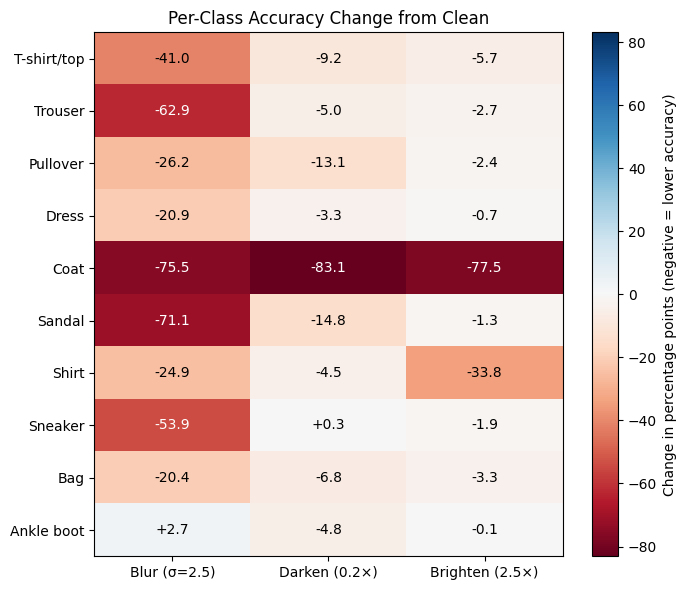


=== 2. High-Confidence Errors (Predicted Confidence >= 0.90) ===
corruption_type  severity  accuracy_%  total_errors  errors_conf_>=0.90  pct_of_errors_>=0.90
           blur       0.5       93.48           652                  91                  14.0
           blur       1.0       76.64          2336                 179                   7.7
           blur       1.5       61.59          3841                 165                   4.3
           blur       2.0       57.21          4279                 133                   3.1
           blur       2.5       55.35          4465                 123                   2.8
       brighten       1.3       91.06           894                 219                  24.5
       brighten       1.6       87.01          1299                 316                  24.3
       brighten       2.0       83.83          1617                 389                  24.1
       brighten       2.5       81.82          1818                 422                 

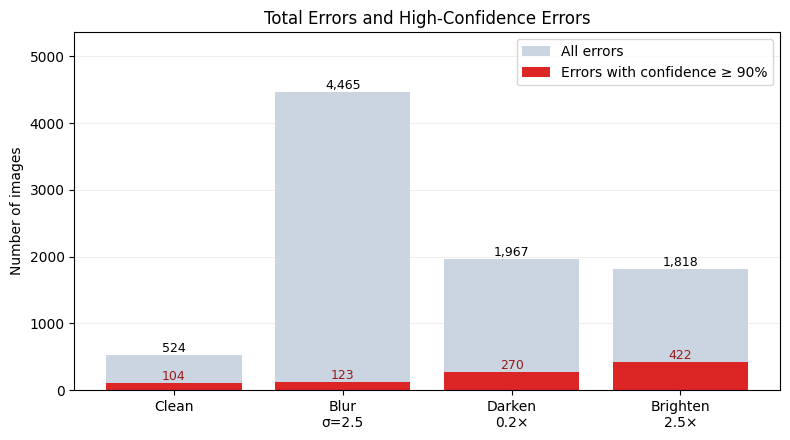


=== 3. Top 5 Error Transitions (True -> Pred) at Worst Severity ===

-- blur (2.5) --
                       count  mean_conf
true_label pred_label                  
Trouser    Dress         482      0.477
Sneaker    Ankle boot    400      0.607
Coat       Pullover      386      0.519
Sandal     Ankle boot    364      0.583
Coat       Shirt         349      0.641

-- darken (0.2) --
                        count  mean_conf
true_label  pred_label                  
Coat        Shirt         461      0.679
            Pullover      304      0.701
Pullover    Shirt         163      0.674
Sandal      Sneaker       145      0.730
T-shirt/top Shirt         144      0.666

-- brighten (2.5) --
                         count  mean_conf
true_label  pred_label                   
Coat        Pullover       663      0.799
Shirt       Pullover       258      0.723
            T-shirt/top    176      0.727
Coat        Dress          109      0.706
T-shirt/top Shirt           90      0.647


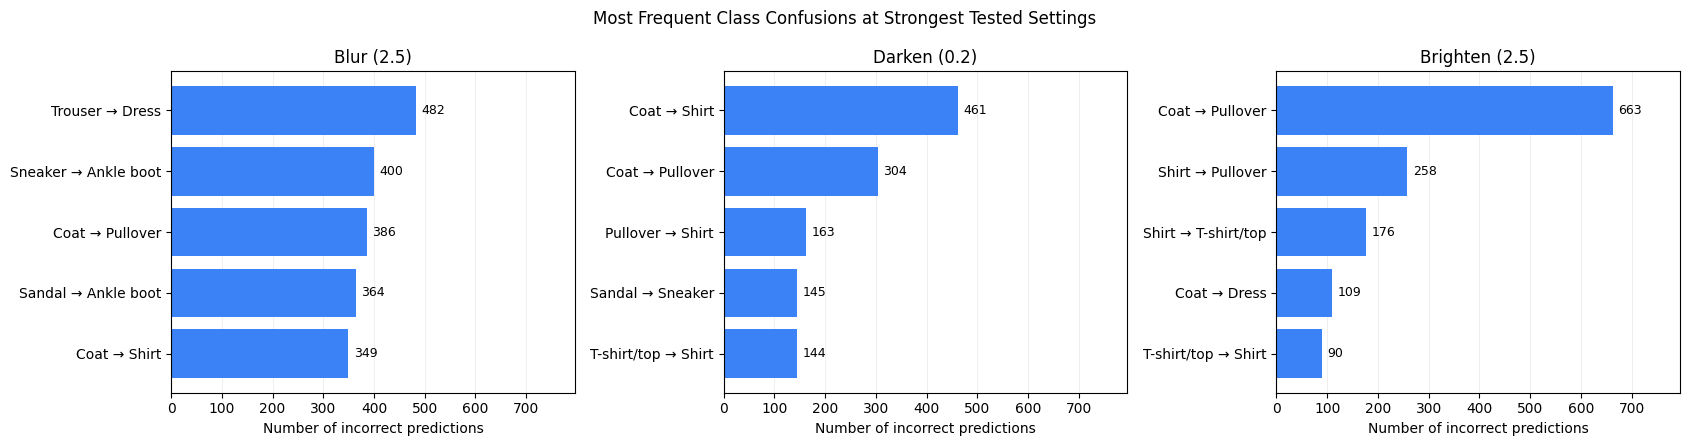

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

if "df" not in globals():
    df = pd.read_csv("/content/phase1_results.csv")

CLASSES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

clean_acc = df[df["corruption_type"] == "clean"].groupby("true_label")["is_correct"].mean()

# 1. Per-class accuracy at worst severity for each corruption track
worst_levels = [("blur", 2.5), ("darken", 0.2), ("brighten", 2.5)]
class_table = pd.DataFrame({"Clean (0.0)": clean_acc})

for c_type, sev in worst_levels:
    sub = df[(df["corruption_type"] == c_type) & (df["severity"] == sev)]
    class_table[f"{c_type} ({sev})"] = sub.groupby("true_label")["is_correct"].mean()
    class_table[f"{c_type} drop"] = class_table[f"{c_type} ({sev})"] - class_table["Clean (0.0)"]

print("=== 1. Per-Class Accuracy & Drop (Clean vs. Worst Severity) ===")
print((class_table.loc[CLASSES] * 100).round(1).to_string())

# Visualization 1: Accuracy change from the clean baseline
drop_columns = [f"{c_type} drop" for c_type, _ in worst_levels]
drop_values = class_table.loc[CLASSES, drop_columns] * 100

fig, ax = plt.subplots(figsize=(7, 6))

color_limit = max(drop_values.abs().max().max(), 1)
heatmap = ax.imshow(
    drop_values.values,
    cmap="RdBu",
    vmin=-color_limit,
    vmax=color_limit,
    aspect="auto",
)

ax.set_xticks(range(len(worst_levels)))
ax.set_xticklabels([
    "Blur (σ=2.5)", "Darken (0.2×)", "Brighten (2.5×)"
])
ax.set_yticks(range(len(CLASSES)))
ax.set_yticklabels(CLASSES)

for row in range(len(CLASSES)):
    for col in range(len(worst_levels)):
        value = drop_values.iloc[row, col]
        ax.text(
            col, row, f"{value:+.1f}",
            ha="center", va="center",
            color="white" if abs(value) > color_limit * 0.6 else "black",
        )

ax.set_title("Per-Class Accuracy Change from Clean")
fig.colorbar(
    heatmap, ax=ax,
    label="Change in percentage points (negative = lower accuracy)",
)
plt.tight_layout()
plt.show()

# 2. High-confidence error rates across every condition (pred_confidence >= 0.90)
hc_rows = []
for (c_type, sev), grp in df.groupby(["corruption_type", "severity"]):
    wrong = grp[~grp["is_correct"]]
    hc_wrong = wrong[wrong["pred_confidence"] >= 0.90]
    hc_rows.append({
        "corruption_type": c_type,
        "severity": sev,
        "accuracy_%": round(grp["is_correct"].mean() * 100, 2),
        "total_errors": len(wrong),
        "errors_conf_>=0.90": len(hc_wrong),
        "pct_of_errors_>=0.90": round((len(hc_wrong) / max(len(wrong), 1)) * 100, 1),
    })

hc_df = pd.DataFrame(hc_rows).sort_values(["corruption_type", "severity"])
print("\n=== 2. High-Confidence Errors (Predicted Confidence >= 0.90) ===")
print(hc_df.to_string(index=False))

# Visualization 2: Total errors and high-confidence errors
comparison_levels = [("clean", 0.0)] + worst_levels
comparison_labels = [
    "Clean", "Blur\nσ=2.5", "Darken\n0.2×", "Brighten\n2.5×"
]

comparison = (
    hc_df.set_index(["corruption_type", "severity"])
    .loc[comparison_levels]
)

fig, ax = plt.subplots(figsize=(8, 4.5))
positions = range(len(comparison))

ax.bar(
    positions,
    comparison["total_errors"],
    color="#cbd5e1",
    label="All errors",
)

ax.bar(
    positions,
    comparison["errors_conf_>=0.90"],
    color="#dc2626",
    label="Errors with confidence ≥ 90%",
)

for position, (_, row) in enumerate(comparison.iterrows()):
    ax.text(
        position,
        row["total_errors"] + 40,
        f"{int(row['total_errors']):,}",
        ha="center",
        fontsize=9,
    )
    ax.text(
        position,
        row["errors_conf_>=0.90"] + 40,
        f"{int(row['errors_conf_>=0.90']):,}",
        ha="center",
        color="#991b1b",
        fontsize=9,
    )

ax.set_xticks(list(positions))
ax.set_xticklabels(comparison_labels)
ax.set_ylabel("Number of images")
ax.set_title("Total Errors and High-Confidence Errors")
ax.set_ylim(0, comparison["total_errors"].max() * 1.2)
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

# 3. Top 5 directional confusion pairs at each track's worst severity
print("\n=== 3. Top 5 Error Transitions (True -> Pred) at Worst Severity ===")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharex=True)

for ax, (c_type, sev) in zip(axes, worst_levels):
    wrong = df[(df["corruption_type"] == c_type) & (df["severity"] == sev) & (~df["is_correct"])]
    top_pairs = (
        wrong.groupby(["true_label", "pred_label"])
        .agg(count=("image_id", "count"), mean_conf=("pred_confidence", "mean"))
        .sort_values("count", ascending=False)
        .head(5)
    )
    print(f"\n-- {c_type} ({sev}) --")
    print(top_pairs.round(3).to_string())

    # Visualization 3: Most frequent class confusions
    pair_labels = [
        f"{true_label} → {pred_label}"
        for true_label, pred_label in top_pairs.index
    ]

    bars = ax.barh(
        pair_labels,
        top_pairs["count"],
        color="#3b82f6",
    )
    ax.bar_label(bars, padding=4, fontsize=9)
    ax.invert_yaxis()
    ax.set_title(f"{c_type.capitalize()} ({sev})")
    ax.set_xlabel("Number of incorrect predictions")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.margins(x=0.2)

fig.suptitle("Most Frequent Class Confusions at Strongest Tested Settings")
plt.tight_layout()
plt.show()